# 151 · Whole-body control on the Unitree G1: why humanoid VLAs need a low-level "System 0"

In [1]:
import numpy as np, mujoco, mujoco_menagerie as mm, matplotlib.pyplot as plt
from vlacourse import show_video, show_images

def g1():
    m = mm.load("unitree_g1"); d = mujoco.MjData(m)
    mujoco.mj_resetDataKeyframe(m, d, m.key("stand").id); mujoco.mj_forward(m, d)
    return m, d

def run(m, d, ctrl_fn, T=3.0, push=None, render=False):
    frames, height, r = [], [], mujoco.Renderer(m, 240, 320) if render else None
    pelvis = m.body("pelvis").id
    while d.time < T:
        d.ctrl[:] = ctrl_fn(m, d)
        d.xfrc_applied[pelvis, :3] = push[1] if push and push[0][0] <= d.time < push[0][1] else 0
        mujoco.mj_step(m, d)
        height.append(d.xpos[pelvis, 2])
        if render and len(frames) < d.time * 25:
            cam = mujoco.MjvCamera(); cam.lookat[:] = d.xpos[pelvis]; cam.distance, cam.azimuth, cam.elevation = 2.5, 140, -10
            r.update_scene(d, cam); frames.append(r.render())
    return np.array(height), frames

In [2]:
m, d = g1()
print(f"G1: {m.nq} position coordinates (7 for the floating base), {m.nv} velocities, {m.nu} actuated joints")
print("actuators:", [m.actuator(i).name for i in range(m.nu)])
stand = m.key("stand").qpos[7:].copy()

G1: 36 position coordinates (7 for the floating base), 35 velocities, 29 actuated joints
actuators: ['left_hip_pitch_joint', 'left_hip_roll_joint', 'left_hip_yaw_joint', 'left_knee_joint', 'left_ankle_pitch_joint', 'left_ankle_roll_joint', 'right_hip_pitch_joint', 'right_hip_roll_joint', 'right_hip_yaw_joint', 'right_knee_joint', 'right_ankle_pitch_joint', 'right_ankle_roll_joint', 'waist_yaw_joint', 'waist_roll_joint', 'waist_pitch_joint', 'left_shoulder_pitch_joint', 'left_shoulder_roll_joint', 'left_shoulder_yaw_joint', 'left_elbow_joint', 'left_wrist_roll_joint', 'left_wrist_pitch_joint', 'left_wrist_yaw_joint', 'right_shoulder_pitch_joint', 'right_shoulder_roll_joint', 'right_shoulder_yaw_joint', 'right_elbow_joint', 'right_wrist_roll_joint', 'right_wrist_pitch_joint', 'right_wrist_yaw_joint']


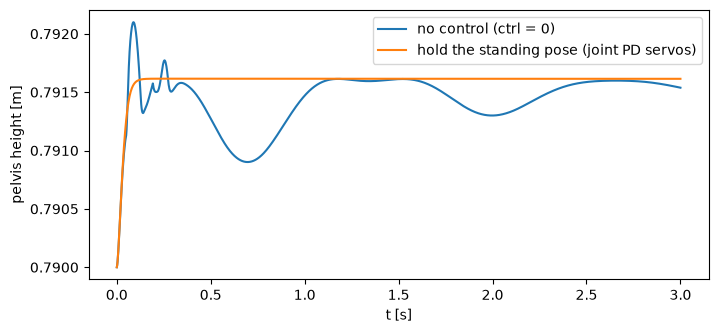

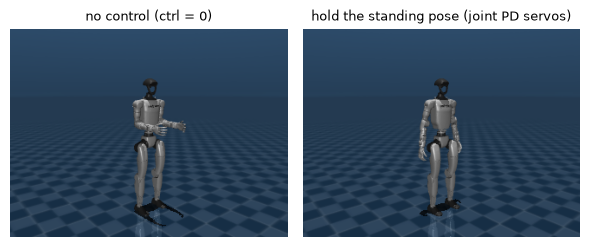

In [3]:
results = {}
for name, fn in [("no control (ctrl = 0)", lambda m, d: np.zeros(m.nu)),
                 ("hold the standing pose (joint PD servos)", lambda m, d: stand)]:
    m, d = g1(); h, f = run(m, d, fn, render=True); results[name] = (h, f)
plt.figure(figsize=(8, 3.5))
for name, (h, _) in results.items():
    plt.plot(np.arange(len(h)) * m.opt.timestep, h, label=name)
plt.ylabel("pelvis height [m]"); plt.xlabel("t [s]"); plt.legend(); plt.show()
show_images([results[n][1][-1] for n in results], list(results), cols=2)

In [4]:
for force in [20, 60, 120]:
    m, d = g1(); h, f = run(m, d, lambda m, d: stand, T=4.0, push=((1.0, 1.2), [force, 0, 0]), render=force == 120)
    print(f"{force:4d} N push for 0.2 s: pelvis height at the end {h[-1]:.2f} m -> {'fell' if h[-1] < 0.5 else 'stayed up'}")
show_video(f, fps=25, title="G1, 120 N push, joint PD only")

  20 N push for 0.2 s: pelvis height at the end 0.79 m -> stayed up
  60 N push for 0.2 s: pelvis height at the end 0.06 m -> fell


 120 N push for 0.2 s: pelvis height at the end 0.09 m -> fell


raising one arm with joint PD only: pelvis height at the end 0.79 m (the centre of mass moves; nothing re-balances)


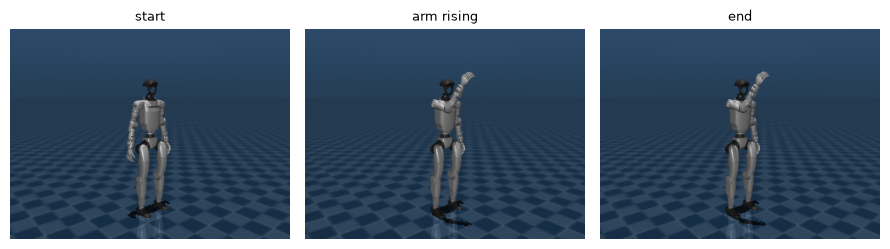

In [5]:
m, d = g1()
def reach(m, d):
    c = stand.copy(); s = min(1.0, d.time / 1.5)
    for j, target in [("right_shoulder_pitch_joint", -1.4), ("right_elbow_joint", 0.2)]:
        idx = [i for i in range(m.nu) if m.actuator(i).name == j][0]; c[idx] = (1 - s) * stand[idx] + s * target
    return c
h, f = run(m, d, reach, T=3.0, render=True)
print(f"raising one arm with joint PD only: pelvis height at the end {h[-1]:.2f} m (the centre of mass moves; nothing re-balances)")
show_images([f[0], f[len(f) // 2], f[-1]], ["start", "arm rising", "end"], cols=3)